# ECG Heartbeat Classification - Exploratory Data Analysis (Task 1, CRISP-DM stage 2-3)

**Project:** Edge-Ready ECG Classification using CRISP-DM  
**Dataset:** MIT-BIH Arrhythmia Database (PhysioNet) + MIT-BIH Noise Stress Test Database  

**Rule used in this notebook:** DS2 (final test set) is used only for *descriptive counts* (class distribution tables), never to tune anything.

Sections (they follow the report structure of the task):
1. Setup
2. Dataset description (task 2.1)
3. Example ECG signal (2.3)
4. Target classes and class distribution (2.2, 2.3, 3.6)
5. Example heartbeats and window size (2.3, 3.3)
6. Amplitude distribution, record and channel differences (2.3, 2.4, 3.2)
7. Noise: real noisy regions and NSTDB noise (2.3, 2.4)
8. Data quality (2.4)
9. Leakage analysis (2.5)
10. Check of the processed dataset (3.4, 3.8, 3.9)
11. Summary

## 1. Setup

In [1]:
import os, sys, json, platform
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import wfdb
from scipy import signal as scipy_signal

sys.path.append('../src')          # prepare_data.py lives in ../src (single source of truth for the config)
sys.path.append('.')
import prepare_data as pdp

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 10

RANDOM_SEED = pdp.RANDOM_SEED
np.random.seed(RANDOM_SEED)
rng = np.random.default_rng(RANDOM_SEED)

DATA_DIR      = os.environ.get('ECG_DATA_DIR', '../data/raw')
PROCESSED_DIR = os.environ.get('ECG_PROCESSED_DIR', '../data/processed')
NOISE_DIR     = os.environ.get('ECG_NOISE_DIR', '../data/nstdb')

FS = pdp.SAMPLING_FREQ
DS1, DS2 = pdp.DS1_RECORDS, pdp.DS2_RECORDS
TRAIN, VAL = pdp.TRAIN_RECORDS, pdp.VALIDATION_RECORDS
ALL_RECORDS = DS1 + DS2
ANNOTATION_MAP = pdp.ANNOTATION_MAP
CLASSES = pdp.CLASS_ORDER
CLASS_NAMES = {'N': 'Normal', 'S': 'Supraventricular', 'V': 'Ventricular', 'F': 'Fusion'}
CLASS_COLORS = {'N': '#2ecc71', 'S': '#3498db', 'V': '#e74c3c', 'F': '#f39c12'}

print('Software versions:', pdp.software_versions(), '| matplotlib', matplotlib.__version__)
print('Seed:', RANDOM_SEED, '| fs:', FS, 'Hz | input length:', pdp.INPUT_LENGTH)
print(f'DS1: {len(DS1)} records (train {len(TRAIN)}, val {len(VAL)}) | DS2: {len(DS2)} records')

/opt/anaconda3/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.9/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Software versions: {'python': '3.9.13', 'numpy': '1.26.4', 'scipy': '1.13.1', 'pandas': '2.3.3', 'wfdb': '4.1.2'} | matplotlib 3.9.4
Seed: 42 | fs: 360 Hz | input length: 360
DS1: 22 records (train 18, val 4) | DS2: 22 records


## 2. Dataset description (task 2.1)

The MIT-BIH Arrhythmia Database has 48 half-hour two-channel recordings from 47 subjects, sampled at 360 Hz with expert beat-by-beat annotations.
We use the **44 records of the DS1/DS2 split**. Records 102, 104, 107 and 217 (paced patients) are not part of the standard split and are not used.
The table below is read from the files, not typed by hand.

In [2]:
# Load every record once (header + annotations) and cache the signals.
RECORDS, ANNS = {}, {}
for rid in ALL_RECORDS:
    try:
        RECORDS[rid] = wfdb.rdrecord(os.path.join(DATA_DIR, rid))
        ANNS[rid] = wfdb.rdann(os.path.join(DATA_DIR, rid), 'atr')
    except Exception as e:
        print(f'Could not load {rid}: {e}')
print(f'Loaded {len(RECORDS)} / {len(ALL_RECORDS)} records')

def split_of(rid):
    return 'Train' if rid in TRAIN else 'Validation' if rid in VAL else 'Test' if rid in DS2 else '?'

def lead_signal(rid, lead=pdp.TARGET_LEAD):
    """Signal of a lead selected BY NAME (MLII is channel 1 in records 114 and 232!)."""
    rec = RECORDS[rid]
    names = list(rec.sig_name)
    return rec.p_signal[:, names.index(lead)] if lead in names else rec.p_signal[:, 0]

info = pd.DataFrame([{
    'record': rid, 'split': split_of(rid), 'fs': r.fs, 'channels': r.n_sig,
    'leads': '/'.join(r.sig_name), 'MLII is channel': (list(r.sig_name).index('MLII') if 'MLII' in r.sig_name else None),
    'duration_min': round(r.sig_len / r.fs / 60, 2), 'n_annotations': len(ANNS[rid].sample)
} for rid, r in RECORDS.items()])
display(info)

print('\nSummary (task 2.1):')
print('  records used          :', len(info))
print('  channels              :', [int(v) for v in sorted(info['channels'].unique())])
print('  sampling frequency    :', [int(v) for v in sorted(info['fs'].unique())], 'Hz')
print(f'  duration              : {info.duration_min.mean():.1f} min on average')
print('  total annotations     :', int(info.n_annotations.sum()))
print('  lead pairs in records :', info['leads'].value_counts().to_dict())
print('  records where MLII is NOT channel 0:', info.loc[info['MLII is channel'] != 0, 'record'].tolist())
print('  records without MLII  :', info.loc[info['MLII is channel'].isna(), 'record'].tolist())

Loaded 44 / 44 records


,record,split,fs,channels,leads,MLII is channel,duration_min,n_annotations
0,101,Train,360,2,MLII/V1,0,30.09,1874
1,106,Train,360,2,MLII/V1,0,30.09,2098
2,108,Train,360,2,MLII/V1,0,30.09,1824
3,109,Train,360,2,MLII/V1,0,30.09,2535
4,112,Train,360,2,MLII/V1,0,30.09,2550
5,114,Train,360,2,V5/MLII,1,30.09,1890
6,115,Train,360,2,MLII/V1,0,30.09,1962
7,116,Train,360,2,MLII/V1,0,30.09,2421
8,118,Train,360,2,MLII/V1,0,30.09,2301
9,119,Train,360,2,MLII/V1,0,30.09,2094



Summary (task 2.1):
  records used          : 44
  channels              : [2]
  sampling frequency    : [360] Hz
  duration              : 30.1 min on average
  total annotations     : 103724
  lead pairs in records : {'MLII/V1': 38, 'MLII/V5': 2, 'MLII/V2': 2, 'V5/MLII': 1, 'MLII/V4': 1}
  records where MLII is NOT channel 0: ['114']
  records without MLII  : []


The lead order is not the same in every record. In records 114 MLII is the *second* channel,
so "always take channel 0" would feed a different lead for those records. `prepare_data.py` therefore selects MLII **by name**; if a record had no MLII it would fall back to channel 0 and report it.

## 3. Example ECG signal

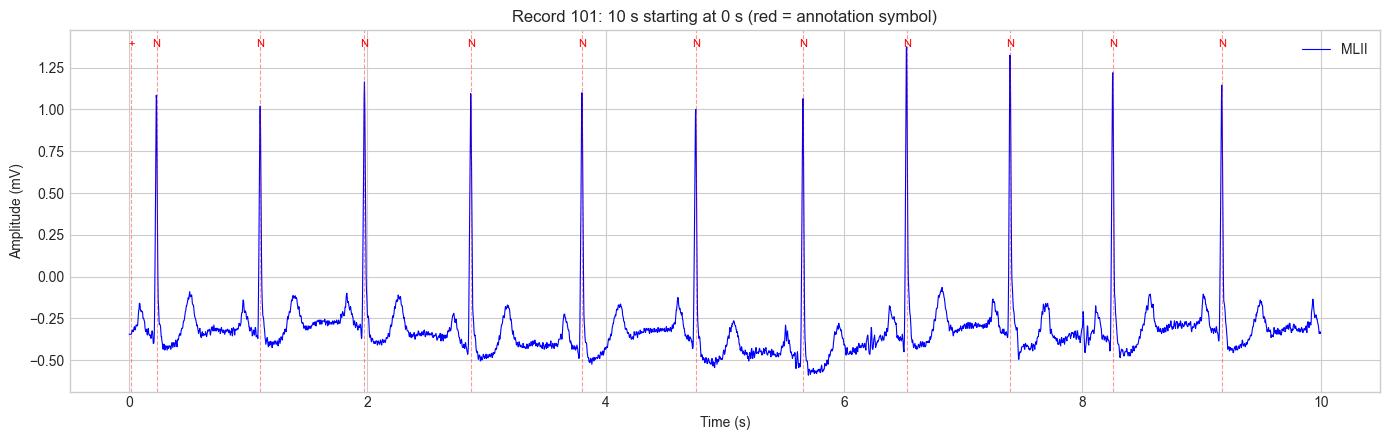

In [3]:
def plot_ecg_signal(rid, start_sec=0, duration_sec=10):
    fs = RECORDS[rid].fs
    a, b = int(start_sec * fs), int((start_sec + duration_sec) * fs)
    t = np.arange(a, b) / fs
    sig = lead_signal(rid)[a:b]
    fig, ax = plt.subplots(figsize=(14, 4.5))
    ax.plot(t, sig, 'b-', lw=0.8, label=f'{pdp.TARGET_LEAD}')
    ann = ANNS[rid]
    for s, sym in zip(ann.sample, ann.symbol):
        if a <= s < b:
            ax.axvline(s / fs, color='r', ls='--', alpha=0.4, lw=0.8)
            ax.annotate(sym, xy=(s / fs, sig.max()), fontsize=8, color='red', ha='center')
    ax.set_xlabel('Time (s)'); ax.set_ylabel('Amplitude (mV)')
    ax.set_title(f'Record {rid}: {duration_sec} s starting at {start_sec} s (red = annotation symbol)')
    ax.legend(); plt.tight_layout(); plt.show()

ex_rec = DS1[0]
plot_ecg_signal(ex_rec, 0, 10)

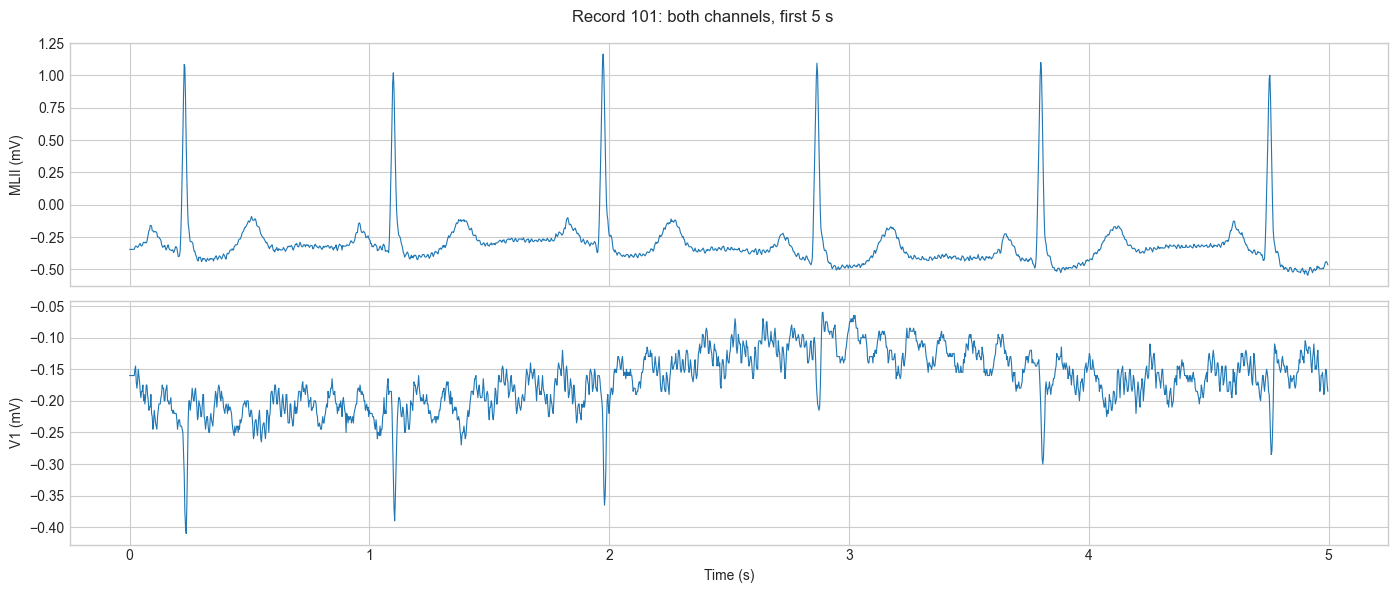

In [4]:
# Both channels of one record (task 2.4: differences between channels)
rid = ex_rec; rec = RECORDS[rid]
fig, axes = plt.subplots(rec.n_sig, 1, figsize=(14, 3 * rec.n_sig), sharex=True)
for i in range(rec.n_sig):
    axes[i].plot(np.arange(5 * FS) / FS, rec.p_signal[:5 * FS, i], lw=0.8)
    axes[i].set_ylabel(f'{rec.sig_name[i]} (mV)')
axes[-1].set_xlabel('Time (s)')
plt.suptitle(f'Record {rid}: both channels, first 5 s'); plt.tight_layout(); plt.show()

## 4. Target classes and class distribution (tasks 2.2, 2.3, 3.5, 3.6)
### 4.1 Complete annotation -> class mapping, with exclusions

In [5]:
# Count EVERY annotation symbol in the 44 records and show what happens to it.
sym_counts = Counter()
for ann in ANNS.values():
    sym_counts.update(ann.symbol)

rows = []
for sym, n in sym_counts.items():
    if sym in ANNOTATION_MAP:
        final, why = ANNOTATION_MAP[sym], 'used'
    elif sym in pdp.EXCLUDED_BEAT_SYMBOLS:
        final, why = 'EXCLUDED', 'paced / unclassifiable beat, not one of N,S,V,F'
    elif sym in pdp.NON_BEAT_SYMBOLS:
        final, why = 'EXCLUDED', 'not a heartbeat (rhythm / quality / wave mark)'
    else:
        final, why = 'EXCLUDED', 'UNKNOWN symbol - check!'
    rows.append({'final_class': final, 'symbol': sym, 'description': pdp.SYMBOL_DESCRIPTIONS.get(sym, '?'),
                 'n_annotations': n, 'reason': why})
mapping = pd.DataFrame(rows)
mapping['o'] = mapping.final_class.map({'N': 0, 'S': 1, 'V': 2, 'F': 3, 'EXCLUDED': 4})
mapping = mapping.sort_values(['o', 'n_annotations'], ascending=[True, False]).drop(columns='o').reset_index(drop=True)
display(mapping)

print('\nTable 2.2 (final class | original annotations | number of annotations):')
t22 = (mapping[mapping.final_class.isin(CLASSES)].groupby('final_class')
       .agg(symbols=('symbol', lambda s: ', '.join(s)), n_beats=('n_annotations', 'sum')).reindex(CLASSES))
display(t22)
n_excl = mapping[mapping.final_class == 'EXCLUDED']
print('Excluded paced/unclassifiable beats :', int(n_excl[n_excl.symbol.isin(pdp.EXCLUDED_BEAT_SYMBOLS)].n_annotations.sum()))
print('Excluded non-beat annotations       :', int(n_excl[n_excl.symbol.isin(pdp.NON_BEAT_SYMBOLS)].n_annotations.sum()))
print('Unknown symbols (must be 0)         :', int(n_excl[~n_excl.symbol.isin(pdp.EXCLUDED_BEAT_SYMBOLS + pdp.NON_BEAT_SYMBOLS)].n_annotations.sum()))

,final_class,symbol,description,n_annotations,reason
0,N,N,Normal beat,74546,used
1,N,L,Left bundle branch block beat,8075,used
2,N,R,Right bundle branch block beat,7259,used
3,N,j,Nodal (junctional) escape beat,229,used
4,N,e,Atrial escape beat,16,used
5,S,A,Atrial premature beat,2546,used
6,S,a,Aberrated atrial premature beat,150,used
7,S,J,Nodal (junctional) premature beat,83,used
8,S,S,Supraventricular premature beat,2,used
9,V,V,Premature ventricular contraction,6903,used



Table 2.2 (final class | original annotations | number of annotations):


,symbols,n_beats
final_class,,
N,"N, L, R, j, e",90125
S,"A, a, J, S",2781
V,"V, E",7009
F,F,803


Excluded paced/unclassifiable beats : 15
Excluded non-beat annotations       : 2991
Unknown symbols (must be 0)         : 0


In [6]:
# Beat-level table: one row per mapped beat
rows = []
for rid, ann in ANNS.items():
    for s, sym in zip(ann.sample, ann.symbol):
        if sym in ANNOTATION_MAP:
            rows.append((rid, int(s), sym, ANNOTATION_MAP[sym], split_of(rid)))
df_beats = pd.DataFrame(rows, columns=['record', 'sample', 'original', 'mapped', 'split'])
print('Mapped beats:', len(df_beats))

Mapped beats: 100718


### 4.2 Class distribution

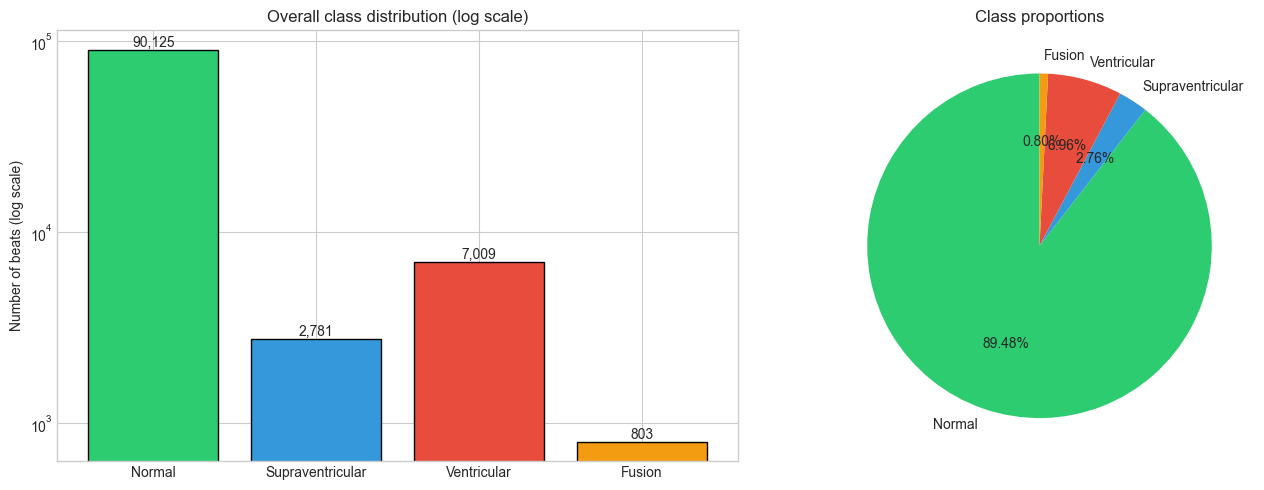

mapped,N,S,V,F,Total
split,,,,,
Train,36417,774,3150,400,40741
Validation,9449,170,638,15,10272
Test,44259,1837,3221,388,49705


mapped,N %,S %,V %,F %
split,,,,
Train,89.39,1.90,7.73,0.98
Validation,91.99,1.65,6.21,0.15
Test,89.04,3.70,6.48,0.78


In [7]:
counts = df_beats['mapped'].value_counts().reindex(CLASSES)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
bars = axes[0].bar([CLASS_NAMES[c] for c in CLASSES], counts.values, color=[CLASS_COLORS[c] for c in CLASSES], edgecolor='black')
axes[0].set_yscale('log'); axes[0].set_ylabel('Number of beats (log scale)'); axes[0].set_title('Overall class distribution (log scale)')
for b in bars:
    axes[0].text(b.get_x() + b.get_width() / 2, b.get_height(), f'{int(b.get_height()):,}', ha='center', va='bottom')
axes[1].pie(counts.values, labels=[CLASS_NAMES[c] for c in CLASSES], colors=[CLASS_COLORS[c] for c in CLASSES],
            autopct='%1.2f%%', startangle=90)
axes[1].set_title('Class proportions')
plt.tight_layout(); plt.show()

by_split = df_beats.groupby(['split', 'mapped']).size().unstack(fill_value=0).reindex(['Train', 'Validation', 'Test'])[CLASSES]
by_split['Total'] = by_split.sum(axis=1)
display(by_split)
display((by_split[CLASSES].div(by_split[CLASSES].sum(axis=1), axis=0) * 100).round(2).add_suffix(' %'))

In [8]:
# Imbalance ratio w.r.t. the training set (what the model will actually see)
tr = by_split.loc['Train', CLASSES]
imb = pd.DataFrame({'train_count': tr, 'share_%': (tr / tr.sum() * 100).round(2),
                    'N : class ratio': (tr['N'] / tr).round(1),
                    'balanced weight': (tr.sum() / (4 * tr)).round(2)})
display(imb)

,train_count,share_%,N : class ratio,balanced weight
mapped,,,,
N,36417,89.39,1.0,0.28
S,774,1.90,47.1,13.16
V,3150,7.73,11.6,3.23
F,400,0.98,91.0,25.46


### 4.3 Record (subject) distribution

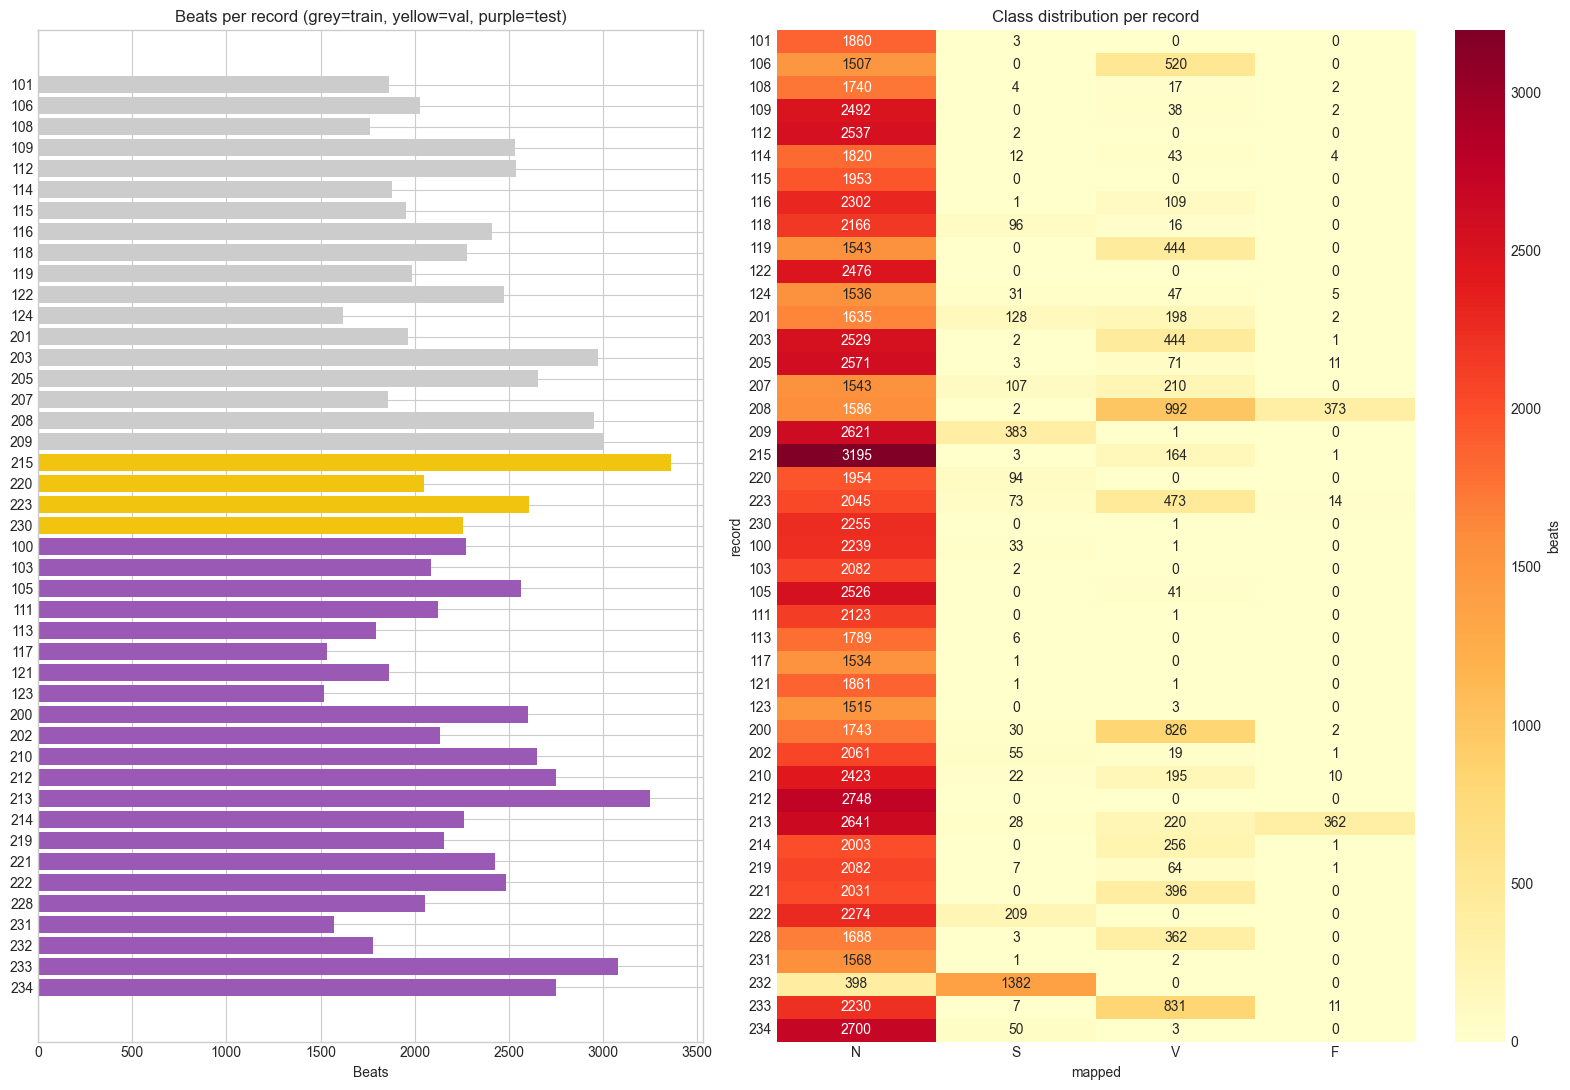

Records without any S beat : ['106', '109', '115', '119', '122', '230', '105', '111', '123', '212', '214', '221']
Records without any F beat : ['101', '106', '112', '115', '116', '118', '119', '122', '207', '209', '220', '230', '100', '103', '105', '111', '113', '117', '121', '123', '212', '221', '222', '228', '231', '232', '234']
Records that hold >50% of all F beats: []
Validation records, minority counts:


mapped,N,S,V,F
record,,,,
215,3195,3,164,1
220,1954,94,0,0
223,2045,73,473,14
230,2255,0,1,0


In [9]:
rec_class = df_beats.groupby(['record', 'mapped']).size().unstack(fill_value=0).reindex(columns=CLASSES, fill_value=0)
rec_class = rec_class.reindex(ALL_RECORDS).fillna(0).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(16, 11), gridspec_kw={'width_ratios': [1, 1.2]})
colors = ['#cccccc' if r in TRAIN else '#f1c40f' if r in VAL else '#9b59b6' for r in rec_class.index]
axes[0].barh(rec_class.index, rec_class.sum(axis=1), color=colors)
axes[0].invert_yaxis(); axes[0].set_xlabel('Beats'); axes[0].set_title('Beats per record (grey=train, yellow=val, purple=test)')
sns.heatmap(rec_class, annot=True, fmt='d', cmap='YlOrRd', ax=axes[1], cbar_kws={'label': 'beats'})
axes[1].set_title('Class distribution per record'); plt.tight_layout(); plt.show()

print('Records without any S beat :', rec_class.index[rec_class['S'] == 0].tolist())
print('Records without any F beat :', rec_class.index[rec_class['F'] == 0].tolist())
print('Records that hold >50% of all F beats:', rec_class.index[rec_class['F'] > 0.5 * rec_class['F'].sum()].tolist())
print('Validation records, minority counts:'); display(rec_class.loc[VAL])

## 5. Example heartbeats and window size (tasks 2.3, 3.3)

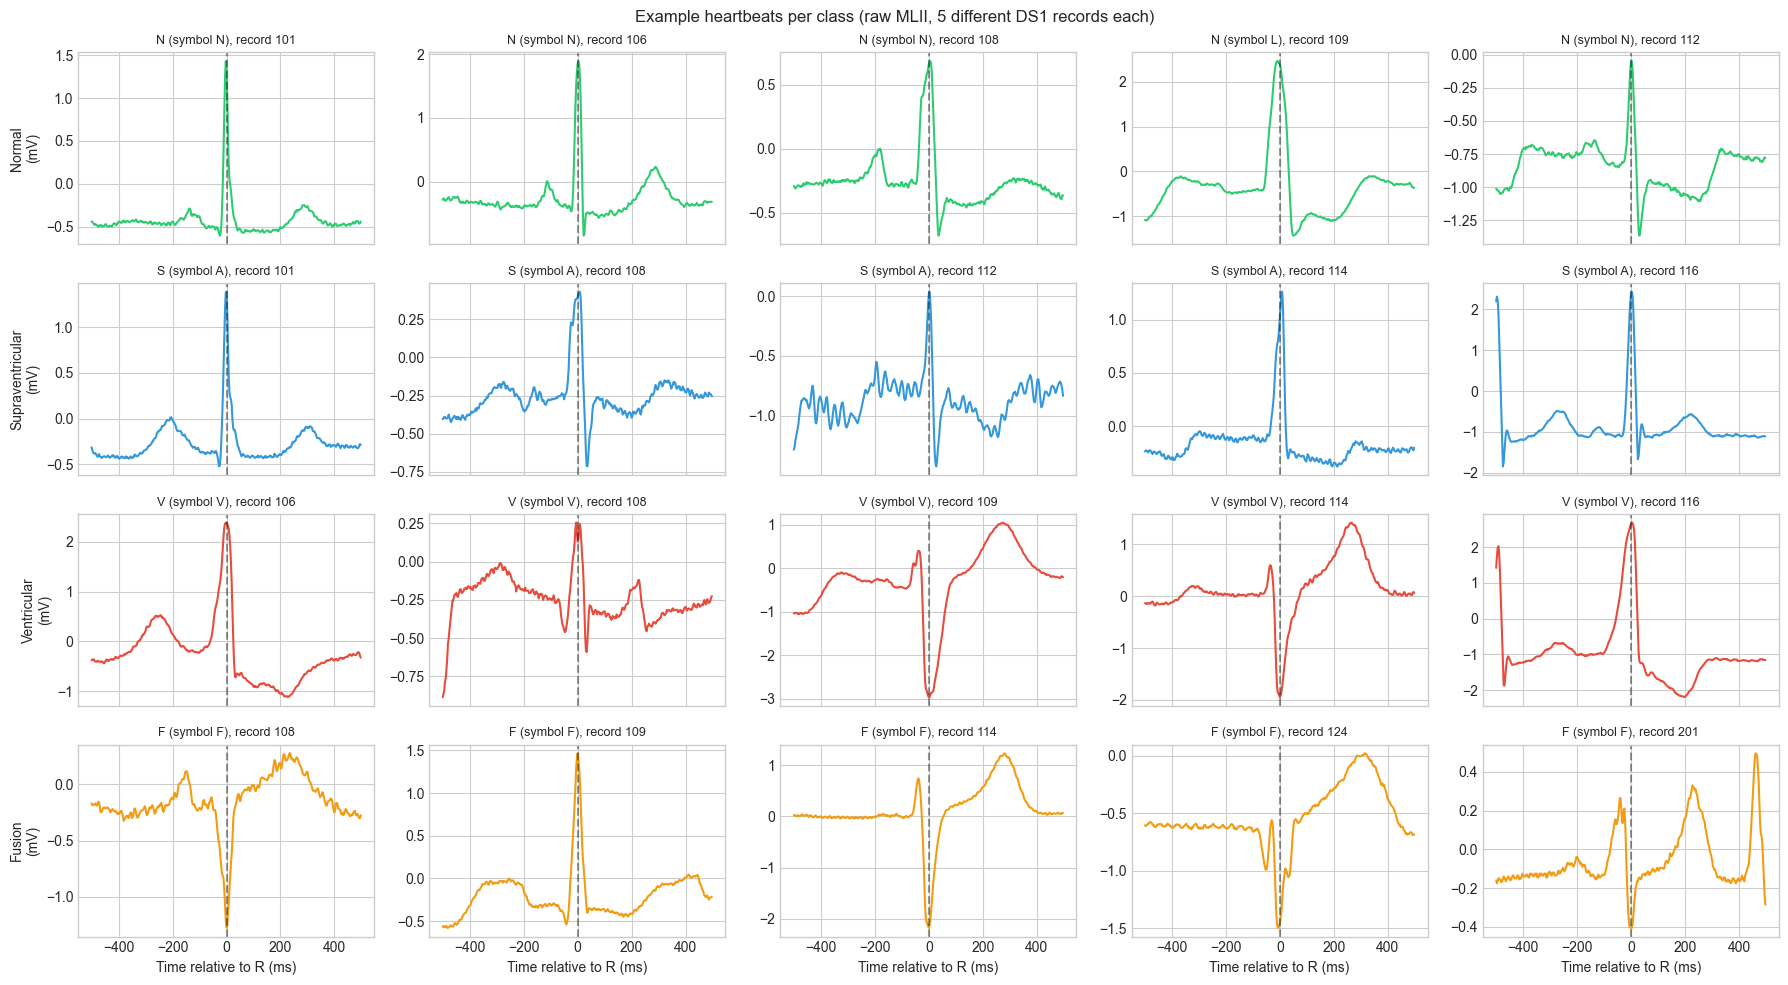

In [10]:
HALF_B, HALF_A = pdp.SAMPLES_BEFORE_R, pdp.SAMPLES_AFTER_R
time_ms = np.arange(-HALF_B, HALF_A + 1) / FS * 1000

def get_segment(rid, sample):
    sig = lead_signal(rid)
    a, b = sample - HALF_B, sample + HALF_A + 1
    return None if a < 0 or b > len(sig) else sig[a:b]

def class_examples(cls, n=5, records=DS1):
    """n examples from n DIFFERENT DS1 records (design decisions use DS1 only)."""
    out = []
    sub = df_beats[(df_beats.mapped == cls) & (df_beats.record.isin(records))]
    for rid in sub.record.unique():
        r = sub[sub.record == rid].sample(1, random_state=RANDOM_SEED).iloc[0]
        seg = get_segment(rid, r['sample'])
        if seg is not None:
            out.append((rid, r['original'], seg))
        if len(out) == n:
            break
    return out

fig, axes = plt.subplots(4, 5, figsize=(18, 10), sharex=True)
for i, cls in enumerate(CLASSES):
    for j, (rid, sym, seg) in enumerate(class_examples(cls)):
        axes[i, j].plot(time_ms, seg, color=CLASS_COLORS[cls]); axes[i, j].axvline(0, color='k', ls='--', alpha=0.4)
        axes[i, j].set_title(f'{cls} (symbol {sym}), record {rid}', fontsize=9)
    axes[i, 0].set_ylabel(f'{CLASS_NAMES[cls]}\n(mV)')
for ax in axes[-1]: ax.set_xlabel('Time relative to R (ms)')
plt.suptitle('Example heartbeats per class (raw MLII, 5 different DS1 records each)'); plt.tight_layout(); plt.show()

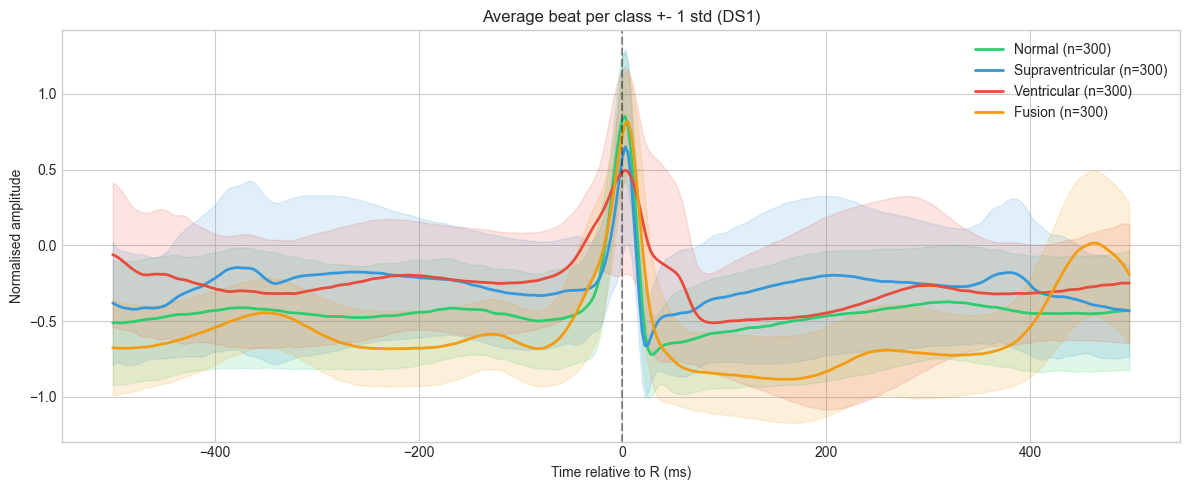

In [11]:
# Average beat per class (DS1, up to 300 random beats per class, per-beat min-max like in the pipeline)
def minmax(x): return 2 * (x - x.min()) / (x.max() - x.min() + 1e-10) - 1

fig, ax = plt.subplots(figsize=(12, 5))
for cls in CLASSES:
    sub = df_beats[(df_beats.mapped == cls) & (df_beats.record.isin(DS1))]
    sub = sub.sample(min(300, len(sub)), random_state=RANDOM_SEED)
    segs = [get_segment(r.record, r.sample) for r in sub.itertuples()]
    segs = np.array([minmax(s) for s in segs if s is not None])
    m, s = segs.mean(0), segs.std(0)
    ax.plot(time_ms, m, color=CLASS_COLORS[cls], lw=2, label=f'{CLASS_NAMES[cls]} (n={len(segs)})')
    ax.fill_between(time_ms, m - s, m + s, color=CLASS_COLORS[cls], alpha=0.15)
ax.axvline(0, color='k', ls='--', alpha=0.4); ax.set_xlabel('Time relative to R (ms)'); ax.set_ylabel('Normalised amplitude')
ax.set_title('Average beat per class +- 1 std (DS1)'); ax.legend(); plt.tight_layout(); plt.show()

In [12]:
# Window-size justification: how often does a 360-sample window contain a NEIGHBOURING beat?
rr_rows = []
for rid in DS1:
    ann = ANNS[rid]
    beat_samples = np.array([s for s, sym in zip(ann.sample, ann.symbol) if sym in ANNOTATION_MAP])
    if len(beat_samples) < 3: continue
    rr = np.diff(beat_samples) / FS
    rr_rows.append({'record': rid, 'median_RR_s': np.median(rr), 'HR_bpm': 60 / np.median(rr),
                    'prev_R_inside_window_%': 100 * np.mean(np.diff(beat_samples) <= HALF_B),
                    'next_R_inside_window_%': 100 * np.mean(np.diff(beat_samples) <= HALF_A)})
rr_df = pd.DataFrame(rr_rows).set_index('record').round(2)
display(rr_df.describe().loc[['min', 'mean', 'max']])
print('A 1.0 s window (180 before / 179 after R) covers one full P-QRS-T complex at normal heart rates; '
      'at high heart rates it also contains parts of the neighbouring beats (see the percentages above).')

,median_RR_s,HR_bpm,prev_R_inside_window_%,next_R_inside_window_%
min,0.530,53.470000,0.000000,0.000000
mean,0.805,77.340909,5.196818,4.933182
max,1.120,112.500000,36.440000,36.170000


A 1.0 s window (180 before / 179 after R) covers one full P-QRS-T complex at normal heart rates; at high heart rates it also contains parts of the neighbouring beats (see the percentages above).


## 6. Amplitude distribution, differences between recordings and between channels (tasks 2.3, 2.4, 3.2)

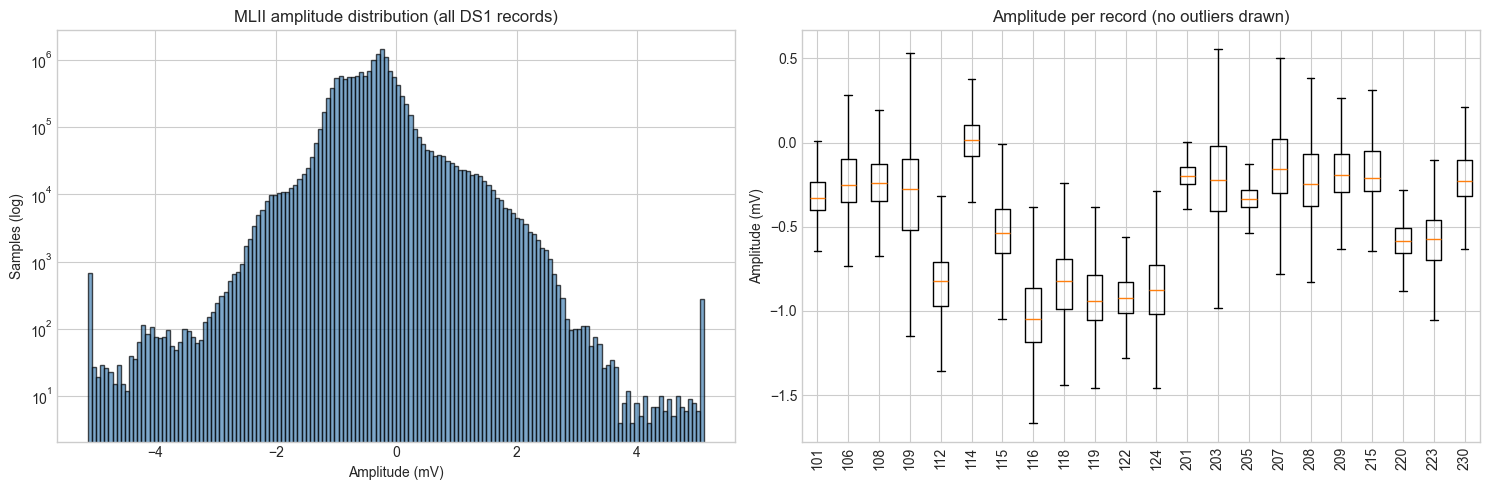

Mean -0.408 mV | std 0.494 mV | min -5.12 | max 5.12


In [13]:
# Amplitude distribution of the selected lead, DS1 records only
amps = {rid: lead_signal(rid) for rid in DS1 if rid in RECORDS}
all_amp = np.concatenate(list(amps.values()))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].hist(all_amp, bins=150, color='steelblue', edgecolor='black', alpha=0.7)
axes[0].set_yscale('log'); axes[0].set_xlabel('Amplitude (mV)'); axes[0].set_ylabel('Samples (log)'); axes[0].set_title('MLII amplitude distribution (all DS1 records)')
bp = axes[1].boxplot(list(amps.values()), showfliers=False)
axes[1].set_xticks(range(1, len(amps) + 1)); axes[1].set_xticklabels(list(amps.keys()), rotation=90)
axes[1].set_ylabel('Amplitude (mV)'); axes[1].set_title('Amplitude per record (no outliers drawn)')
plt.tight_layout(); plt.show()
print(f'Mean {all_amp.mean():.3f} mV | std {all_amp.std():.3f} mV | min {all_amp.min():.2f} | max {all_amp.max():.2f}')

,mean_mV,std_mV,p01,p99,range_mV
min,-0.936000,0.165000,-2.220000,-0.165000,2.320000
mean,-0.344455,0.357545,-1.112159,1.128182,5.101705
max,0.069000,0.671000,-0.465000,2.275000,10.235000


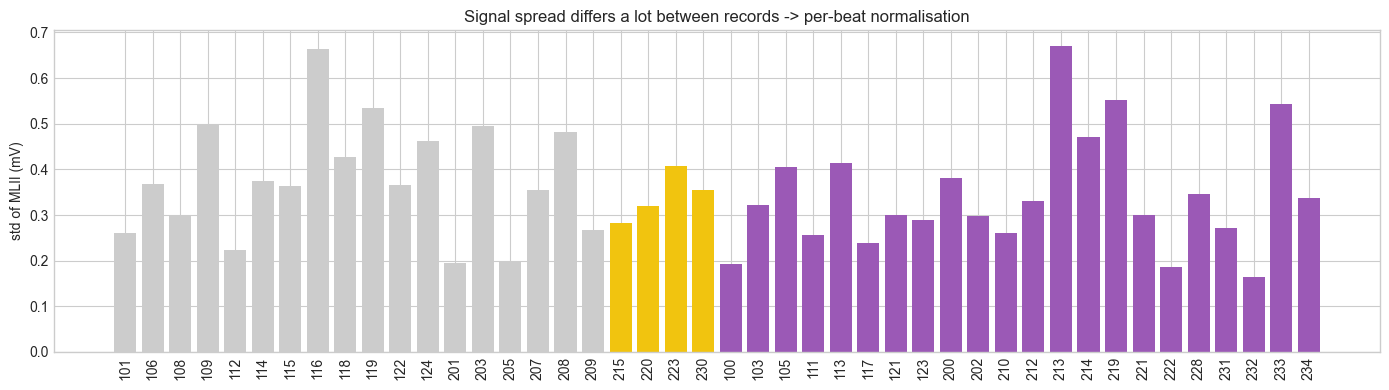

In [14]:
# Differences between RECORDINGS (selected lead): offset, spread, heart rate
rows = []
for rid in ALL_RECORDS:
    if rid not in RECORDS: continue
    s = lead_signal(rid)
    rows.append({'record': rid, 'split': split_of(rid), 'mean_mV': s.mean(), 'std_mV': s.std(),
                 'p01': np.percentile(s, 1), 'p99': np.percentile(s, 99), 'range_mV': s.max() - s.min()})
rec_stats = pd.DataFrame(rows).set_index('record').round(3)
display(rec_stats.describe().loc[['min', 'mean', 'max']])
fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(rec_stats.index, rec_stats['std_mV'], color=['#cccccc' if split_of(r) == 'Train' else '#f1c40f' if split_of(r) == 'Validation' else '#9b59b6' for r in rec_stats.index])
ax.set_ylabel('std of MLII (mV)'); ax.set_title('Signal spread differs a lot between records -> per-beat normalisation'); plt.xticks(rotation=90); plt.tight_layout(); plt.show()

,MLII_name,other_lead,std_MLII,std_other,QRS_ptp_MLII,QRS_ptp_other,corr
record,,,,,,,
101,MLII,V1,0.261,0.049,1.875,0.135,-0.234
106,MLII,V1,0.368,0.137,2.375,0.510,0.120
108,MLII,V1,0.301,0.505,1.170,1.435,-0.066
109,MLII,V1,0.499,0.332,2.420,1.410,-0.743
112,MLII,V1,0.224,0.108,1.230,0.475,-0.106
114,MLII,V5,0.375,0.171,2.320,0.740,0.201
115,MLII,V1,0.363,0.245,3.190,0.545,0.016
116,MLII,V1,0.664,0.230,3.930,0.885,-0.286
118,MLII,V1,0.428,0.349,2.728,2.195,0.129


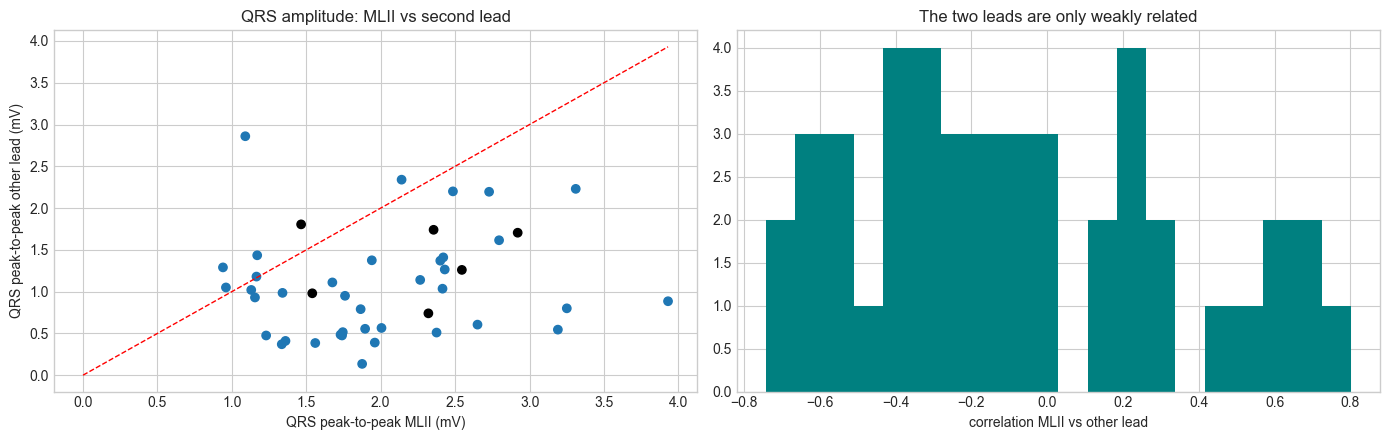

Second leads in use: {'V1': 38, 'V5': 3, 'V2': 2, 'V4': 1}
MLII has the larger QRS than the other lead in 37 of 44 records


In [15]:
# Differences between CHANNELS: MLII vs the second lead
rows = []
for rid in ALL_RECORDS:
    if rid not in RECORDS: continue
    rec = RECORDS[rid]; names = list(rec.sig_name)
    i_m = names.index('MLII') if 'MLII' in names else 0
    i_o = 1 - i_m
    a, b = rec.p_signal[:, i_m], rec.p_signal[:, i_o]
    # QRS amplitude proxy: median of (max-min) in +-100 ms around annotated beats
    ann = ANNS[rid]
    peaks = [s for s, sym in zip(ann.sample, ann.symbol) if sym in ANNOTATION_MAP and 36 < s < len(a) - 36]
    qa = np.median([np.ptp(a[s-36:s+36]) for s in peaks]); qb = np.median([np.ptp(b[s-36:s+36]) for s in peaks])
    rows.append({'record': rid, 'MLII_name': names[i_m], 'other_lead': names[i_o], 'std_MLII': a.std(), 'std_other': b.std(),
                 'QRS_ptp_MLII': qa, 'QRS_ptp_other': qb, 'corr': np.corrcoef(a, b)[0, 1]})
chan = pd.DataFrame(rows).set_index('record').round(3)
display(chan.head(10))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].scatter(chan.QRS_ptp_MLII, chan.QRS_ptp_other, c=['k' if o != 'V1' else 'tab:blue' for o in chan.other_lead])
lim = max(chan.QRS_ptp_MLII.max(), chan.QRS_ptp_other.max()); axes[0].plot([0, lim], [0, lim], 'r--', lw=1)
axes[0].set_xlabel('QRS peak-to-peak MLII (mV)'); axes[0].set_ylabel('QRS peak-to-peak other lead (mV)'); axes[0].set_title('QRS amplitude: MLII vs second lead')
axes[1].hist(chan['corr'], bins=20, color='teal'); axes[1].set_xlabel('correlation MLII vs other lead'); axes[1].set_title('The two leads are only weakly related')
plt.tight_layout(); plt.show()
print('Second leads in use:', chan.other_lead.value_counts().to_dict())
print('MLII has the larger QRS than the other lead in', int((chan.QRS_ptp_MLII > chan.QRS_ptp_other).sum()), 'of', len(chan), 'records')

**Decision for task 3.2:** use **MLII** for all records. It exists in all 44 records, it is the standard beat-classification lead, and the second lead is
different from record to record (V1, V2, V4, V5, ...), so it cannot be treated as one consistent input. Selection is **by lead name**; if a record had no MLII, channel 0 would be used and flagged (`lead_fallback` in `per_record_statistics.csv`).

## 7. Noise (tasks 2.3, 2.4)

### 7.1 Real noisy regions inside MIT-BIH (annotation `~` = change in signal quality)

In [16]:
q = pd.DataFrame([{'record': rid, 'split': split_of(rid),
                   '~ signal-quality marks': int(np.sum(np.array(ANNS[rid].symbol) == '~')),
                   '| isolated artifacts': int(np.sum(np.array(ANNS[rid].symbol) == '|'))} for rid in ANNS]).set_index('record')
display(q[(q.iloc[:, 1:] > 0).any(axis=1)])
print('Records with at least one quality mark:', int((q.iloc[:, 1:] > 0).any(axis=1).sum()), '/', len(q))

,split,~ signal-quality marks,| isolated artifacts
record,,,
101,Train,4,4
106,Train,30,0
108,Train,41,8
109,Train,2,0
112,Train,10,0
114,Train,7,1
115,Train,2,6
116,Train,8,0
118,Train,12,0


Records with at least one quality mark: 38 / 44


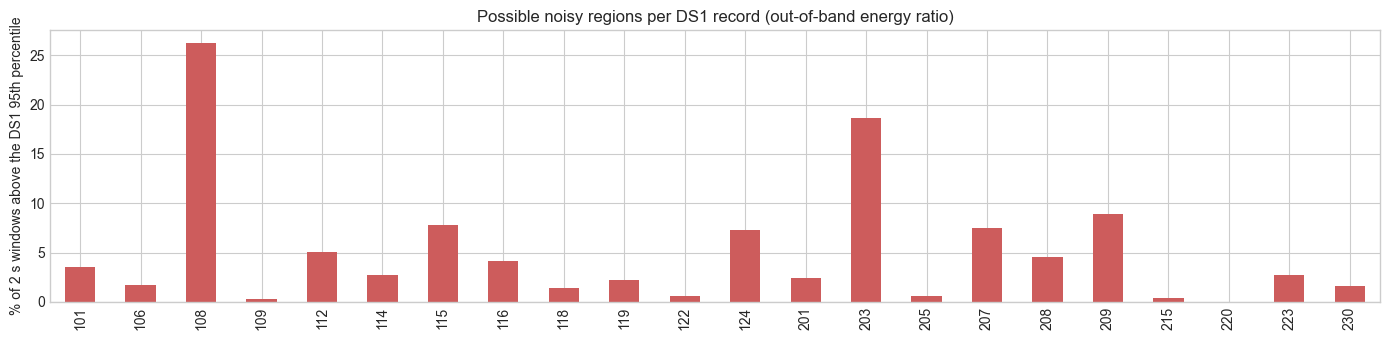

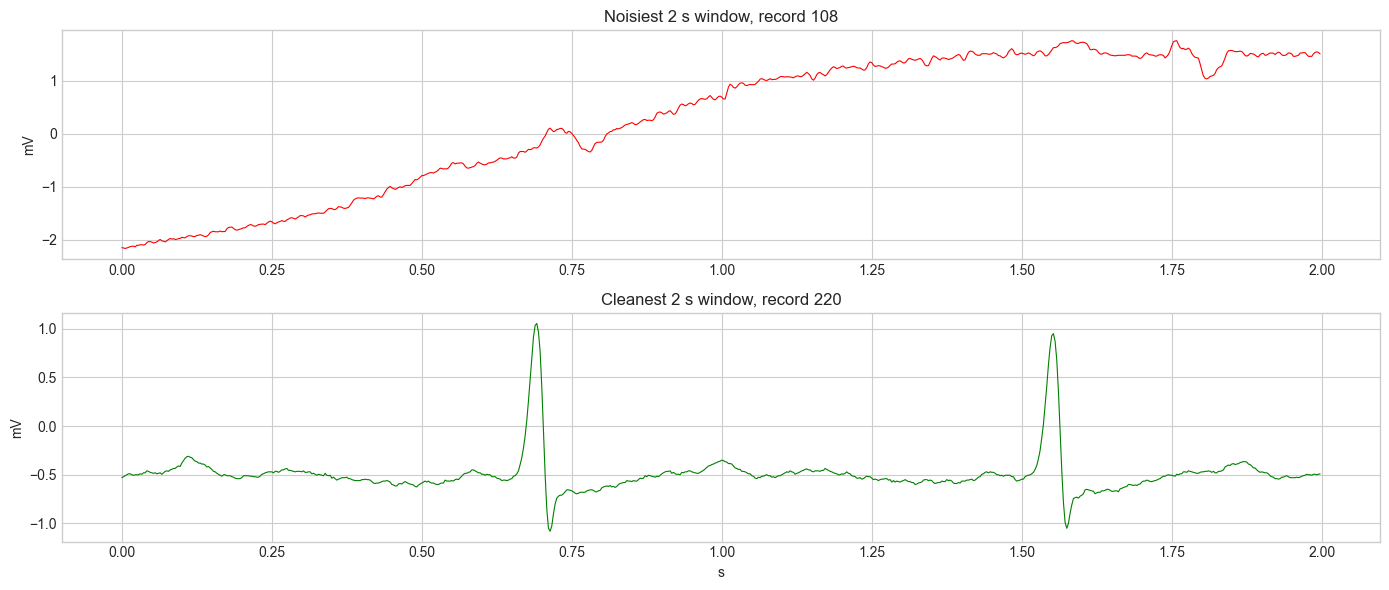

In [17]:
# Noise level per 2-second window: std of what the 0.5-40 Hz band-pass REMOVES, relative to the band-passed signal
sos = pdp.design_bandpass_sos()
def window_noise_ratio(sig, win=2 * FS):
    bp = scipy_signal.sosfiltfilt(sos, sig)
    resid = sig - bp - np.mean(sig - bp)
    n = len(sig) // win
    return np.array([np.std(resid[i*win:(i+1)*win]) / (np.std(bp[i*win:(i+1)*win]) + 1e-9) for i in range(n)])

nr = {rid: window_noise_ratio(lead_signal(rid)) for rid in DS1 if rid in RECORDS}
thr = np.percentile(np.concatenate(list(nr.values())), 95)
noisy_frac = pd.Series({rid: 100 * np.mean(v > thr) for rid, v in nr.items()}).round(1)
fig, ax = plt.subplots(figsize=(14, 3.5)); noisy_frac.plot.bar(ax=ax, color='indianred')
ax.set_ylabel('% of 2 s windows above the DS1 95th percentile'); ax.set_title('Possible noisy regions per DS1 record (out-of-band energy ratio)'); plt.tight_layout(); plt.show()

rid_noisy = noisy_frac.idxmax()
w = int(np.argmax(nr[rid_noisy])); s = lead_signal(rid_noisy)
rid_clean = noisy_frac.idxmin(); wc = int(np.argmin(nr[rid_clean])); sc = lead_signal(rid_clean)
fig, axes = plt.subplots(2, 1, figsize=(14, 6))
axes[0].plot(np.arange(2 * FS) / FS, s[w*2*FS:(w+1)*2*FS], 'r', lw=0.8); axes[0].set_title(f'Noisiest 2 s window, record {rid_noisy}')
axes[1].plot(np.arange(2 * FS) / FS, sc[wc*2*FS:(wc+1)*2*FS], 'g', lw=0.8); axes[1].set_title(f'Cleanest 2 s window, record {rid_clean}')
for a in axes: a.set_ylabel('mV')
axes[1].set_xlabel('s'); plt.tight_layout(); plt.show()

### 7.2 MIT-BIH Noise Stress Test Database (baseline wander `bw`, electrode motion `em`, muscle artifact `ma`)

NSTDB not found - trying to download ...

>> Downloading MIT-BIH Noise Stress Test Database (bw, em, ma)
Generating record list for: bw
Generating record list for: em
Generating record list for: ma
Generating list of all files for: bw
Generating list of all files for: em
Generating list of all files for: ma
Finished downloading files
Loaded noise records: ['bw', 'em', 'ma']


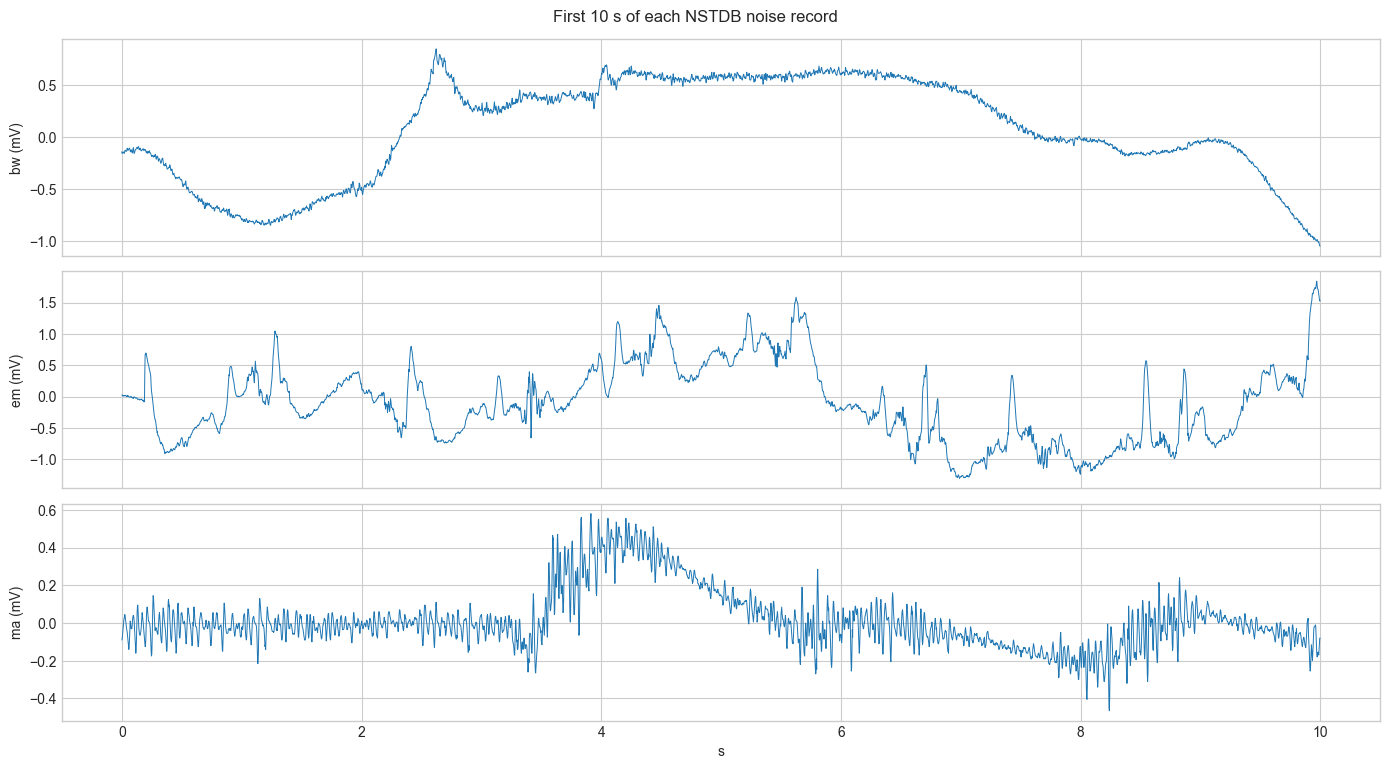

In [18]:
NOISE = {}
if pdp._missing_records(NOISE_DIR, pdp.NSTDB_RECORDS):
    print('NSTDB not found - trying to download ...')
    try: pdp.download_nstdb(NOISE_DIR)
    except Exception as e: print('Download failed:', e)
for nm in pdp.NSTDB_RECORDS:
    try: NOISE[nm] = pdp.load_noise_record(NOISE_DIR, nm)
    except Exception as e: print(f'Noise record {nm} not available: {e}')
print('Loaded noise records:', list(NOISE))

if NOISE:
    fig, axes = plt.subplots(len(NOISE), 1, figsize=(14, 2.6 * len(NOISE)), sharex=True)
    axes = np.atleast_1d(axes)
    for ax, (nm, x) in zip(axes, NOISE.items()):
        ax.plot(np.arange(10 * FS) / FS, x[:10 * FS], lw=0.7); ax.set_ylabel(f'{nm} (mV)')
    axes[-1].set_xlabel('s'); plt.suptitle('First 10 s of each NSTDB noise record'); plt.tight_layout(); plt.show()

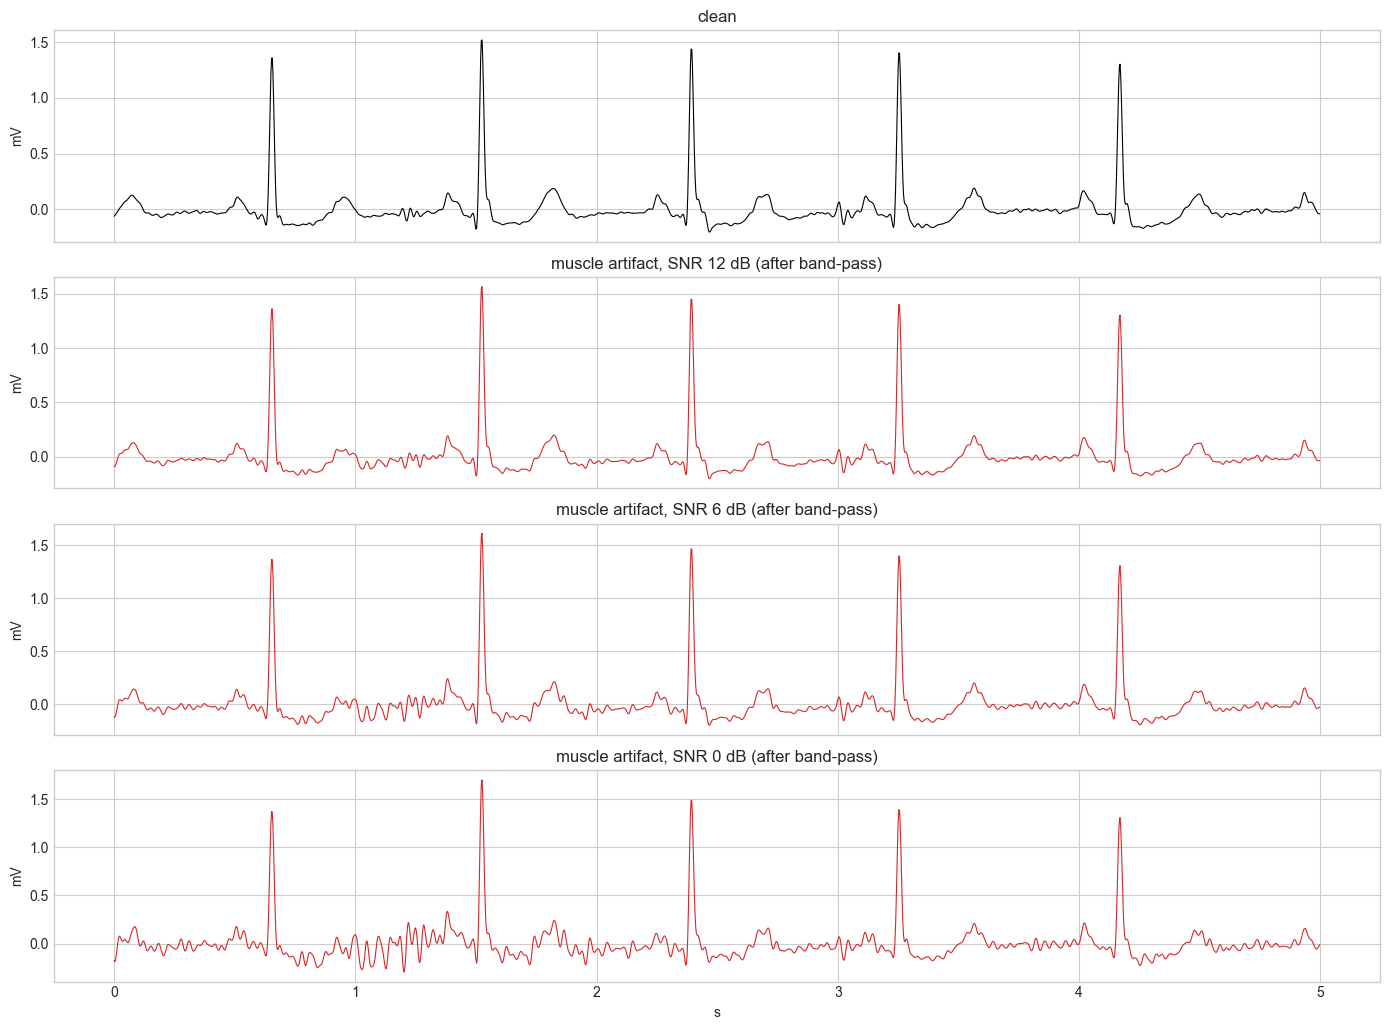

target 12 dB -> measured 12.00 dB
target  6 dB -> measured  6.00 dB
target  0 dB -> measured  0.00 dB


In [19]:
# A clean DS1 ECG with NSTDB noise at 12, 6 and 0 dB (this is how the robustness test sets are built).
# Noise is added to the RAW signal, then the normal band-pass filter is applied.
if NOISE:
    rid = DS1[0]; raw = lead_signal(rid); a, b = 5 * FS, 10 * FS
    _, noise_test = pdp.split_noise_train_test(NOISE['ma'])        # test half of the noise record
    snrs = [None, 12, 6, 0]
    fig, axes = plt.subplots(len(snrs), 1, figsize=(14, 2.6 * len(snrs)), sharex=True)
    for ax, snr in zip(axes, snrs):
        x = raw if snr is None else pdp.add_noise_at_snr(raw, noise_test, snr, np.random.default_rng(RANDOM_SEED))
        y = pdp.apply_bandpass_filter(x)
        ax.plot(np.arange(b - a) / FS, y[a:b], lw=0.8, color='k' if snr is None else 'tab:red')
        ax.set_ylabel('mV'); ax.set_title('clean' if snr is None else f'muscle artifact, SNR {snr} dB (after band-pass)')
    axes[-1].set_xlabel('s'); plt.tight_layout(); plt.show()

    # check the SNR definition numerically
    for snr in [12, 6, 0]:
        noisy = pdp.add_noise_at_snr(raw, noise_test, snr, np.random.default_rng(1))
        p_sig = np.var(pdp.apply_bandpass_filter(raw)); p_noise = np.var(noisy - raw)
        print(f'target {snr:2d} dB -> measured {10*np.log10(p_sig/p_noise):5.2f} dB')

**Noise protocol (no leakage, task 4):** each NSTDB noise record is split in time. The **first half** may be used for training augmentation, the **second half** is used only to create noisy versions of DS2.
Noise is never added to the training data from the test half, and nothing from the noisy test sets is used for model selection.

## 8. Data quality (task 2.4)

In [20]:
rows = []
for rid in ALL_RECORDS:
    if rid not in RECORDS: continue
    rec = RECORDS[rid]; s = lead_signal(rid)
    med = np.median(s); mad = 1.4826 * np.median(np.abs(s - med)) + 1e-9
    win = FS
    flat = sum(np.std(s[i:i+win]) < 1e-3 for i in range(0, len(s) - win, win))
    # fraction of samples a 5-sigma (mean +- 5 std) record-level clip would change, and how many R-peaks it would cut
    m, sd = s.mean(), s.std()
    clipped = np.mean((s > m + 5 * sd) | (s < m - 5 * sd)) * 100
    beats = [x for x, sym in zip(ANNS[rid].sample, ANNS[rid].symbol) if sym in ANNOTATION_MAP and x < len(s)]
    cut_peaks = 100 * np.mean([(s[max(0, x-5):x+6].max() > m + 5 * sd) or (s[max(0, x-5):x+6].min() < m - 5 * sd) for x in beats]) if beats else 0
    rows.append({'record': rid, 'NaN': int(np.isnan(s).sum()), 'flat_1s_windows': flat,
                 'samples |x|>5 mV': int((np.abs(s) > 5).sum()),
                 'robust-z>10 %': round(100 * np.mean(np.abs(s - med) / mad > 10), 2),
                 '5-sigma clip changes samples %': round(clipped, 3), 'beats whose R-peak a 5-sigma clip would cut %': round(cut_peaks, 1)})
quality = pd.DataFrame(rows).set_index('record')
display(quality)
print('Records with NaN:', int((quality.NaN > 0).sum()), '| records with flat windows:', int((quality.flat_1s_windows > 0).sum()))
print(f"Median % of beats whose R-peak a record-level 5-sigma clip would cut: {quality.iloc[:, -1].median():.1f}% (max {quality.iloc[:, -1].max():.1f}%)")

,NaN,flat_1s_windows,samples |x|>5 mV,robust-z>10 %,5-sigma clip changes samples %,beats whose R-peak a 5-sigma clip would cut %
record,,,,,,
101,0,0,0,1.56,1.227,97.5
106,0,0,0,0.96,0.772,47.3
108,0,0,0,0.38,0.462,1.1
109,0,0,0,0.08,0.375,10.9
112,0,0,0,0.00,0.087,2.2
114,0,0,0,2.76,1.086,84.9
115,0,0,0,1.02,1.127,97.1
116,0,0,977,2.71,0.678,31.1
118,0,0,0,0.03,0.036,0.4


Records with NaN: 0 | records with flat windows: 0
Median % of beats whose R-peak a record-level 5-sigma clip would cut: 26.1% (max 99.8%)


**Decision on clipping:** the table above measures what the old record-level 5-sigma clip would do to the R-peaks. An ECG is mostly flat with sparse tall R-peaks, so the record standard deviation is small and a 5-sigma limit can cut the R-peak itself.
If the last column is clearly above 0 for many records, clipping is **off by default** (`--clip-sigma` turns it on); outliers are handled by per-beat min-max normalisation and by rejecting flat-line beats.

## 9. Leakage analysis (task 2.5)

### How leakage could happen here
1. **Random beat split.** Beats of the same patient share heart geometry, electrode position, gain, baseline level and often the *same* abnormal morphology repeated hundreds of times (e.g. one patient has hundreds of near-identical V beats). If beats of one patient are in both train and test, the network can recognise the **patient** instead of the **beat type**. Test accuracy becomes unrealistically high and does not predict performance on new patients.
2. **Neighbouring beats overlap.** A 1 s window around R overlaps with the windows of the previous and next beat, so random splitting can place almost identical samples in train and test.
3. **Hidden same-subject pairs.** The database has 48 records but 47 subjects: **records 201 (DS1) and 202 (DS2) come from the same man**. The standard DS1/DS2 split therefore has one subject in both sets. We keep the standard split because the task requires it, and report this as a known limitation (optional sensitivity check: also evaluate DS2 without record 202).
4. **Preprocessing statistics.** Normalisation computed on the whole dataset would leak test statistics. Here normalisation is **per beat** and class weights are computed on the **training set only**.
5. **Validation and augmentation.** Validation must also be split by record, and augmentation is applied to training data only. Noise for training and test comes from different halves of the NSTDB noise records.

### What we do
DS1 (22 records) is used for training and validation, **split by record** (18 train / 4 validation). DS2 (22 records) is the final test set. No record appears in two sets (checked below, and asserted in `prepare_data.py`).

In [21]:
tr_s, va_s, te_s = set(TRAIN), set(VAL), set(DS2)
print('Train / Val / Test records :', len(tr_s), len(va_s), len(te_s))
print('Train & Val  :', tr_s & va_s)
print('Train & Test :', tr_s & te_s)
print('Val & Test   :', va_s & te_s)
assert not (tr_s & va_s) and not (tr_s & te_s) and not (va_s & te_s)
assert tr_s | va_s == set(DS1)
print('OK: record-independent split verified.')
print('Known caveat: records 201 (train) and 202 (test) are the same subject.')

Train / Val / Test records : 18 4 22
Train & Val  : set()
Train & Test : set()
Val & Test   : set()
OK: record-independent split verified.
Known caveat: records 201 (train) and 202 (test) are the same subject.


In [22]:
# EMPIRICAL DEMONSTRATION on the processed data: random beat split vs record split.
# A small Random Forest is enough. This is a demonstration of leakage, NOT the project's model.
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

try:
    Xtr, ytr = np.load(f'{PROCESSED_DIR}/X_train.npy'), np.load(f'{PROCESSED_DIR}/y_train.npy')
    Xva, yva = np.load(f'{PROCESSED_DIR}/X_val.npy'), np.load(f'{PROCESSED_DIR}/y_val.npy')
    ok = True
except Exception as e:
    print('Processed data not found - run prepare_data.py first:', e); ok = False

if ok:
    def fit_eval(Xa, ya, Xb, yb):
        sub = np.random.default_rng(RANDOM_SEED).choice(len(Xa), min(8000, len(Xa)), replace=False)
        clf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_SEED).fit(Xa[sub], ya[sub])
        p = clf.predict(Xb)
        return accuracy_score(yb, p), f1_score(yb, p, average='macro', labels=[0, 1, 2, 3], zero_division=0)

    # (a) WRONG: random beat split inside the training records
    Xa, Xb, ya, yb = train_test_split(Xtr, ytr, test_size=0.3, random_state=RANDOM_SEED, stratify=ytr)
    acc_r, f1_r = fit_eval(Xa, ya, Xb, yb)
    # (b) RIGHT: train on training records, test on other (validation) records
    acc_p, f1_p = fit_eval(Xtr, ytr, Xva, yva)
    res = pd.DataFrame({'split': ['random beats (leaky)', 'by record (correct)'],
                        'accuracy': [acc_r, acc_p], 'macro-F1': [f1_r, f1_p]}).round(3)
    display(res)
    print('The leaky split looks better because the model has seen the same patients. Only the by-record number is honest.')

,split,accuracy,macro-F1
0,random beats (leaky),0.982,0.869
1,by record (correct),0.924,0.332


The leaky split looks better because the model has seen the same patients. Only the by-record number is honest.


## 10. Check of the processed dataset (tasks 3.4, 3.8, 3.9)

In [23]:
P = {}
if os.path.isdir(PROCESSED_DIR):
    P = pdp.load_processed_data(PROCESSED_DIR)
print('Files loaded:', len(P))
if P:
    stats = pd.read_csv(f'{PROCESSED_DIR}/dataset_statistics.csv')
    print('Table 3.8 - final dataset:'); display(stats.drop(columns='Record IDs'))
    for sp in ['train', 'val', 'test']:
        X, y = P[f'X_{sp}'], P[f'y_{sp}']
        print(f'{sp:5s}: X {X.shape} {X.dtype} | y {y.shape} {y.dtype} | min {X.min():.3f} max {X.max():.3f} | NaN {int(np.isnan(X).sum())} | '
              f'classes {np.bincount(y, minlength=4).tolist()} | records {len(set(P[f"{sp}_record_ids"].tolist()))}')
    assert not (set(P['train_record_ids']) & set(P['val_record_ids']))
    assert not (set(P['train_record_ids']) & set(P['test_record_ids']))
    assert not (set(P['val_record_ids']) & set(P['test_record_ids']))
    assert P['X_train'].shape[1] == pdp.INPUT_LENGTH
    print('OK: shapes, no NaN, no record overlap.')
    print('\nClass weights (train):', P['class_weights'])
    display(pd.read_csv(f'{PROCESSED_DIR}/per_record_statistics.csv').head(12))

Files loaded: 19
Table 3.8 - final dataset:


,Split,Records,N,S,V,F,Total
0,Train,18,36398,774,3150,399,40721
1,Validation,4,9443,170,638,15,10266
2,Test,22,44235,1837,3220,388,49680


train: X (40721, 360) float32 | y (40721,) int64 | min -1.000 max 1.000 | NaN 0 | classes [36398, 774, 3150, 399] | records 18
val  : X (10266, 360) float32 | y (10266,) int64 | min -1.000 max 1.000 | NaN 0 | classes [9443, 170, 638, 15] | records 4
test : X (49680, 360) float32 | y (49680,) int64 | min -1.000 max 1.000 | NaN 0 | classes [44235, 1837, 3220, 388] | records 22
OK: shapes, no NaN, no record overlap.

Class weights (train): {'0': 0.2796925655255783, '1': 13.152777777777779, '2': 3.2318253968253967, '3': 25.514411027568922}


,record,split,leads_in_record,lead_used,lead_fallback,duration_min,N,S,V,F,kept_total,dropped_boundary,dropped_flat,excluded_paced_or_Q,excluded_non_beat,unmapped
0,101,Train,MLII/V1,MLII,False,30.09,1859,3,0,0,1862,1,0,2,9,0
1,106,Train,MLII/V1,MLII,False,30.09,1507,0,520,0,2027,0,0,0,71,0
2,108,Train,MLII/V1,MLII,False,30.09,1739,4,17,2,1762,1,0,0,61,0
3,109,Train,MLII/V1,MLII,False,30.09,2490,0,38,2,2530,2,0,0,3,0
4,112,Train,MLII/V1,MLII,False,30.09,2535,2,0,0,2537,2,0,0,11,0
5,114,Train,V5/MLII,MLII,False,30.09,1820,12,43,4,1879,0,0,0,11,0
6,115,Train,MLII/V1,MLII,False,30.09,1951,0,0,0,1951,2,0,0,9,0
7,116,Train,MLII/V1,MLII,False,30.09,2301,1,109,0,2411,1,0,0,9,0
8,118,Train,MLII/V1,MLII,False,30.09,2165,96,16,0,2277,1,0,0,23,0
9,119,Train,MLII/V1,MLII,False,30.09,1543,0,444,0,1987,0,0,0,107,0


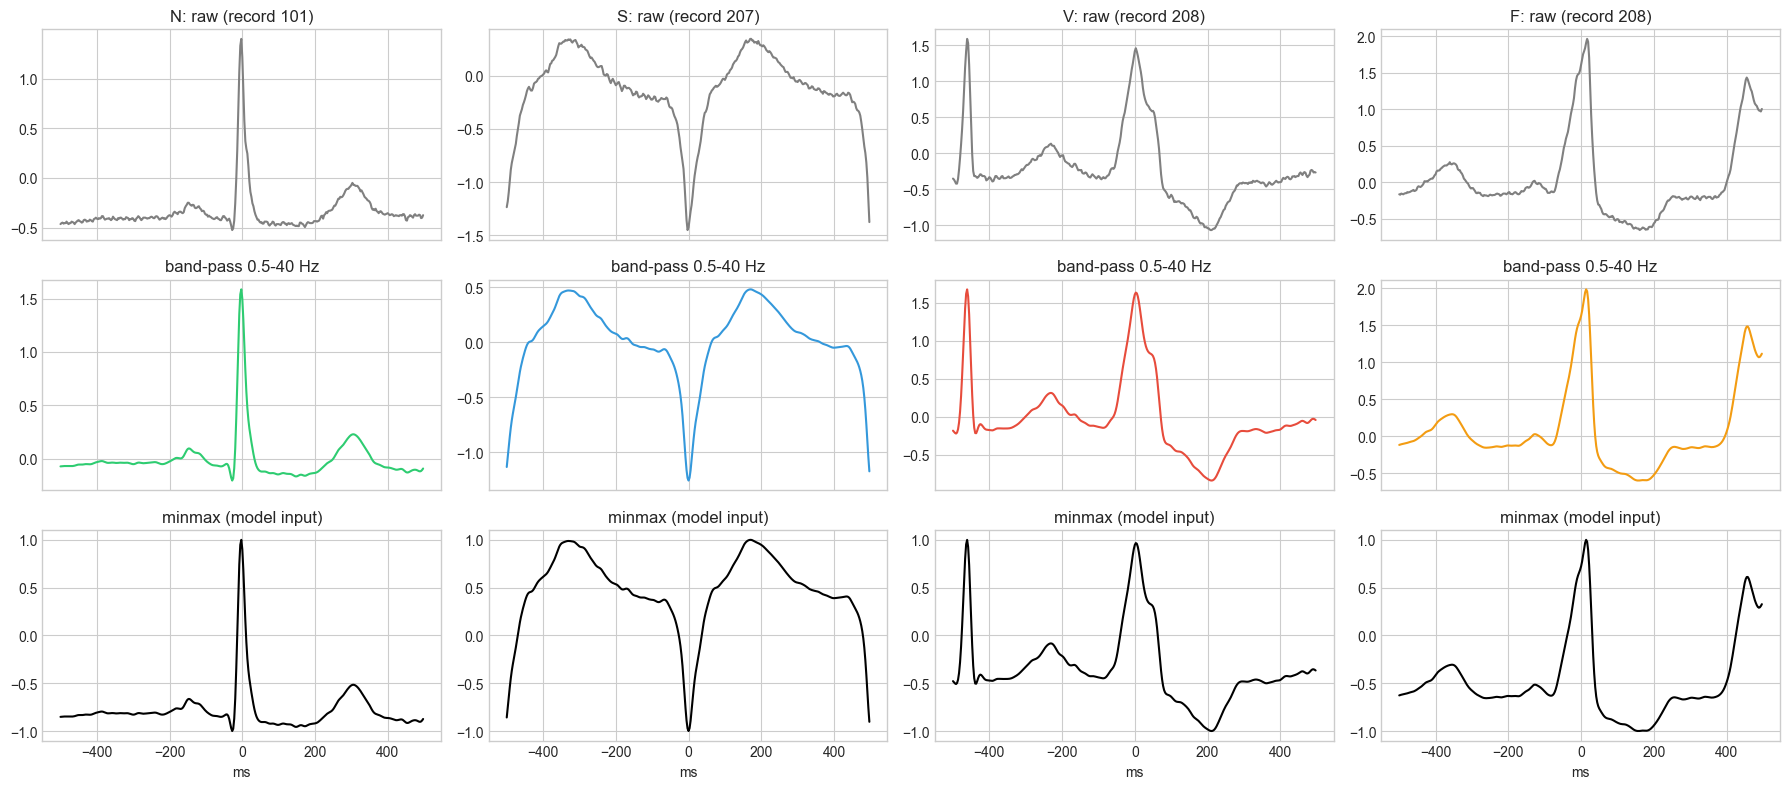

Reproducibility record (task 3.9):
  random_seed: 42
  software_versions: {'python': '3.9.13', 'numpy': '1.26.4', 'scipy': '1.9.1', 'pandas': '1.4.4', 'wfdb': '4.1.2'}
  sampling_frequency: 360
  input_length: 360
  samples_before_r: 180
  samples_after_r: 179
  target_lead: MLII
  filter: {'type': 'Butterworth band-pass (SOS)', 'lowcut_hz': 0.5, 'highcut_hz': 40.0, 'order': 4, 'zero_phase': True}
  normalization_method: minmax
  clip_sigma: None
  pipeline_order: ['(noise injection, noisy test only)', 'band-pass filter', 'optional clipping', 'segmentation', 'flat-beat rejection', 'per-beat normalisation']


In [24]:
# Preprocessing illustration (task 3.4): raw -> band-pass -> segmentation -> normalisation, for one beat of each class
if P:
    cfg = P['preprocessing_config']
    fig, axes = plt.subplots(3, 4, figsize=(18, 8), sharex=True)
    for j, cls in enumerate(CLASSES):
        sub = df_beats[(df_beats.mapped == cls) & (df_beats.record.isin(TRAIN))]
        r = sub.sample(1, random_state=RANDOM_SEED).iloc[0]
        raw = lead_signal(r.record)
        flt = pdp.apply_bandpass_filter(raw, zero_phase=cfg['filter']['zero_phase'])
        a, b = r['sample'] - HALF_B, r['sample'] + HALF_A + 1
        if a < 0 or b > len(raw): continue
        axes[0, j].plot(time_ms, raw[a:b], color='gray'); axes[0, j].set_title(f'{cls}: raw (record {r.record})')
        axes[1, j].plot(time_ms, flt[a:b], color=CLASS_COLORS[cls]); axes[1, j].set_title('band-pass 0.5-40 Hz')
        axes[2, j].plot(time_ms, pdp.normalize_signal(flt[a:b], cfg['normalization_method']), color='k'); axes[2, j].set_title(f"{cfg['normalization_method']} (model input)")
    for ax in axes[-1]: ax.set_xlabel('ms')
    plt.tight_layout(); plt.show()

    print('Reproducibility record (task 3.9):')
    for k in ['random_seed', 'software_versions', 'sampling_frequency', 'input_length', 'samples_before_r', 'samples_after_r',
              'target_lead', 'filter', 'normalization_method', 'clip_sigma', 'pipeline_order']:
        print(f'  {k}: {cfg[k]}')

## 11. Summary

In [25]:
tot = len(df_beats)
print('=' * 64); print('EDA SUMMARY'); print('=' * 64)
print(f'Records: {len(RECORDS)} (DS1 {len(DS1)}, DS2 {len(DS2)}) | fs {FS} Hz | lead {pdp.TARGET_LEAD} (selected by name)')
print(f'Mapped beats: {tot:,}')
for c in CLASSES:
    print(f'  {CLASS_NAMES[c]:17s} ({c}): {int(counts[c]):7,d}  ({counts[c] / tot * 100:5.2f}%)')
print('Splits (beats):', by_split['Total'].to_dict())
print('Exclusions: paced/unclassifiable beats and non-beat annotations are listed in section 4.1')
print('Known issues found: MLII is channel 1 in', info.loc[info['MLII is channel'] == 1, 'record'].tolist(),
      '| 201/202 same subject')
print(f"Validation minority beats (S/V/F): {by_split.loc['Validation', ['S', 'V', 'F']].to_dict()} -> check section 4.3 if any is small")
print('=' * 64)

EDA SUMMARY
Records: 44 (DS1 22, DS2 22) | fs 360 Hz | lead MLII (selected by name)
Mapped beats: 100,718
  Normal            (N):  90,125  (89.48%)
  Supraventricular  (S):   2,781  ( 2.76%)
  Ventricular       (V):   7,009  ( 6.96%)
  Fusion            (F):     803  ( 0.80%)
Splits (beats): {'Train': 40741, 'Validation': 10272, 'Test': 49705}
Exclusions: paced/unclassifiable beats and non-beat annotations are listed in section 4.1
Known issues found: MLII is channel 1 in ['114'] | 201/202 same subject
Validation minority beats (S/V/F): {'S': 170, 'V': 638, 'F': 15} -> check section 4.3 if any is small
